<a href="https://colab.research.google.com/github/Maryam-sudo-png/Computer-Vision-Labs/blob/main/Lab08_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


##  House Price Prediction

**Algorithms compared:** Linear Regression · Decision Tree · Random Forest · Neural Network (MLP) · XGBoost · K-Nearest Neighbors

**Dataset:** California Housing (20,640 samples, 8 features, target = median house value in $100,000s)

**Fair-comparison rules used in this notebook**
- Same dataset, same input features, same target variable
- Same 80:20 train/test split (`random_state=42`) for every model
- Feature scaling (`StandardScaler`, fitted on training data only) for scale-sensitive models: Linear Regression, KNN, Neural Network
- Same metrics for all models: MAE, MSE, RMSE, R²


## 1. Import Libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load the Dataset

In [ ]:
from sklearn.datasets import fetch_california_housing

try:
    data = fetch_california_housing(as_frame=True)
    df = data.frame.copy()
    df.rename(columns={"MedHouseVal": "Price"}, inplace=True)
    print("Loaded California Housing dataset from scikit-learn.")
except Exception as e:
    # Fallback (only used if there is no internet access to download the dataset)
    print("Could not download dataset (", type(e).__name__, "). Using synthetic housing data instead.")
    rng = np.random.default_rng(RANDOM_STATE)
    n = 5000
    df = pd.DataFrame({
        "MedInc": rng.lognormal(1.2, 0.5, n),
        "HouseAge": rng.integers(1, 52, n).astype(float),
        "AveRooms": rng.normal(5.4, 1.2, n).clip(2, 12),
        "AveBedrms": rng.normal(1.1, 0.2, n).clip(0.5, 3),
        "Population": rng.lognormal(7, 0.6, n),
        "AveOccup": rng.normal(3, 0.7, n).clip(1, 8),
        "Latitude": rng.uniform(32.5, 42, n),
        "Longitude": rng.uniform(-124, -114, n),
    })
    df["Price"] = (0.45*df.MedInc + 0.01*df.HouseAge + 0.1*df.AveRooms
                   - 0.05*df.AveOccup - 0.03*(df.Latitude-37)**2
                   + 0.4*np.sin(df.MedInc) + rng.normal(0, 0.3, n)).clip(0.15, 5)

print("Shape:", df.shape)
df.head()

Loaded California Housing dataset from scikit-learn.
Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 3. Exploratory Data Analysis

In [ ]:
print(df.info())
print("\nMissing values per column:\n", df.isnull().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Price       20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None

Missing values per column:
 MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Price         0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
Price,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


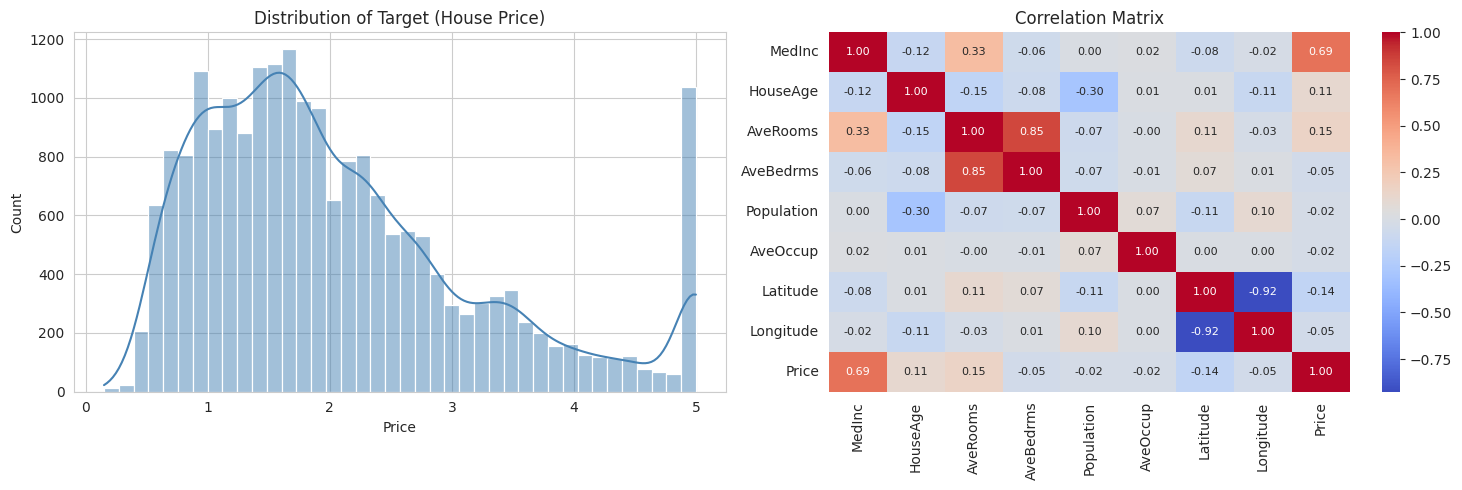

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(df["Price"], bins=40, kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Distribution of Target (House Price)")
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1], annot_kws={"size": 8})
ax[1].set_title("Correlation Matrix")
plt.tight_layout(); plt.show()

## 4. Data Preprocessing
- Missing values: handled (none expected; median imputation is applied as a safeguard)
- Duplicates removed
- Features (X) and target (y) separated
- 80:20 train/test split
- `StandardScaler` fitted **only on training data** (prevents data leakage)

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
df = df.fillna(df.median(numeric_only=True))

TARGET = "Price"
FEATURES = [c for c in df.columns if c != TARGET]
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE)

print("Features :", FEATURES)
print("Train set:", X_train.shape, "| Test set:", X_test.shape)

# Scaled copies for scale-sensitive models (Linear, KNN, Neural Network)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

Features : ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Train set: (16512, 8) | Test set: (4128, 8)


## 5. Evaluation Helper

In [ ]:
results = {}       # metrics for every model
predictions = {}   # test-set predictions for every model

def evaluate(name, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true, y_pred)
    results[name] = {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}
    predictions[name] = np.asarray(y_pred)
    print(f"{name:<20} MAE={mae:.4f} | MSE={mse:.4f} | RMSE={rmse:.4f} | R2={r2:.4f}")

## 6. Model Implementations
### 6.1 Linear Regression
Model: ŷ = β₀ + β₁x₁ + … + βₚxₚ, with coefficients found by minimizing the sum of squared errors (Ordinary Least Squares). Uses **scaled** features.

In [ ]:
lr = LinearRegression()
lr.fit(X_train_sc, y_train)
y_pred_lr = lr.predict(X_test_sc)
evaluate("Linear Regression", y_test, y_pred_lr)

coef = pd.DataFrame({"Feature": FEATURES, "Coefficient": lr.coef_}).sort_values("Coefficient")
print("\nIntercept:", round(lr.intercept_, 4))
coef

Linear Regression    MAE=0.5332 | MSE=0.5559 | RMSE=0.7456 | R2=0.5758

Intercept: 2.0719


,Feature,Coefficient
6,Latitude,-0.896929
7,Longitude,-0.869842
2,AveRooms,-0.294410
5,AveOccup,-0.040829
4,Population,-0.002308
1,HouseAge,0.122546
3,AveBedrms,0.339259
0,MedInc,0.854383


### 6.2 Decision Tree Regression
Recursively splits the data on the feature/threshold that gives the largest reduction in MSE; each leaf predicts the mean of its training targets. Trees are scale-invariant, so **unscaled** features are used. `max_depth` is tuned with 5-fold cross-validation on the training set only to limit overfitting.

In [ ]:
dt_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid={"max_depth": [3, 5, 7, 9, 12, 15], "min_samples_leaf": [1, 5, 10, 20]},
    cv=5, scoring="neg_mean_squared_error", n_jobs=-1)
dt_grid.fit(X_train, y_train)
dt = dt_grid.best_estimator_
print("Best parameters:", dt_grid.best_params_)

y_pred_dt = dt.predict(X_test)
evaluate("Decision Tree", y_test, y_pred_dt)

Best parameters: {'max_depth': 12, 'min_samples_leaf': 20}
Decision Tree        MAE=0.4062 | MSE=0.3611 | RMSE=0.6009 | R2=0.7244


### 6.3 Random Forest Regression
An ensemble of many decision trees, each trained on a bootstrap sample with random feature subsets; the final prediction is the **average** of all trees (bagging), which reduces variance. Uses unscaled features.

In [ ]:
rf = RandomForestRegressor(n_estimators=200, max_depth=None, min_samples_leaf=2,
                           n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
evaluate("Random Forest", y_test, y_pred_rf)

Random Forest        MAE=0.3260 | MSE=0.2540 | RMSE=0.5040 | R2=0.8061


### 6.4 Neural Network Regression (MLP)
A multilayer perceptron with two hidden layers (64 and 32 neurons, ReLU activation) trained with the Adam optimizer and early stopping (10% of training data held out internally for validation). Requires **scaled** features. The target is left unscaled (house prices are in $100k units).

Neural Network       MAE=0.3528 | MSE=0.2709 | RMSE=0.5205 | R2=0.7932


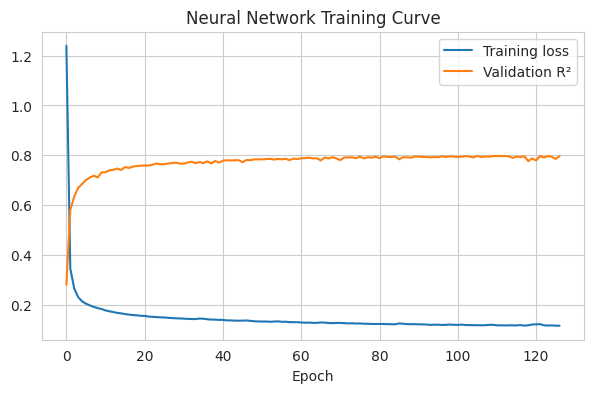

In [ ]:
nn = MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                  learning_rate_init=0.001, max_iter=500, early_stopping=True,
                  validation_fraction=0.1, n_iter_no_change=20, random_state=RANDOM_STATE)
nn.fit(X_train_sc, y_train)
y_pred_nn = nn.predict(X_test_sc)
evaluate("Neural Network", y_test, y_pred_nn)

plt.figure(figsize=(7, 4))
plt.plot(nn.loss_curve_, label="Training loss")
plt.plot(nn.validation_scores_, label="Validation R²")
plt.xlabel("Epoch"); plt.title("Neural Network Training Curve"); plt.legend(); plt.show()

### 6.5 XGBoost Regression
Gradient-boosted trees: trees are added sequentially, each one fitted to the residual errors (gradients) of the current ensemble, with L1/L2 regularization to control overfitting. Unscaled features are used.

In [ ]:
xgb = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6,
                   subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                   objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
evaluate("XGBoost", y_test, y_pred_xgb)

XGBoost              MAE=0.2935 | MSE=0.2005 | RMSE=0.4478 | R2=0.8470


### 6.6 K-Nearest Neighbors Regression
Predicts the **average target value of the k closest training points** (Euclidean distance). It is distance-based, so **scaled** features are essential. The best k is chosen by 5-fold cross-validation on the training set.

In [ ]:
knn_grid = GridSearchCV(
    KNeighborsRegressor(),
    param_grid={"n_neighbors": [3, 5, 7, 9, 11, 15, 21], "weights": ["uniform", "distance"]},
    cv=5, scoring="neg_mean_squared_error", n_jobs=-1)
knn_grid.fit(X_train_sc, y_train)
knn = knn_grid.best_estimator_
print("Best parameters:", knn_grid.best_params_)

y_pred_knn = knn.predict(X_test_sc)
evaluate("KNN", y_test, y_pred_knn)

Best parameters: {'n_neighbors': 11, 'weights': 'distance'}
KNN                  MAE=0.4351 | MSE=0.4136 | RMSE=0.6431 | R2=0.6844


## 7. Comparative Performance Table

In [ ]:
results_df = pd.DataFrame(results).T[["MAE", "MSE", "RMSE", "R2"]]
results_df = results_df.sort_values("R2", ascending=False).round(4)
results_df.index.name = "Model"

display(results_df.style
        .background_gradient(cmap="RdYlGn_r", subset=["MAE", "MSE", "RMSE"])
        .background_gradient(cmap="RdYlGn", subset=["R2"])
        .format("{:.4f}"))

,MAE,MSE,RMSE,R2
Model,,,,
XGBoost,0.2935,0.2005,0.4478,0.8470
Random Forest,0.3260,0.2540,0.5040,0.8061
Neural Network,0.3528,0.2709,0.5205,0.7932
Decision Tree,0.4062,0.3611,0.6009,0.7244
KNN,0.4351,0.4136,0.6431,0.6844
Linear Regression,0.5332,0.5559,0.7456,0.5758


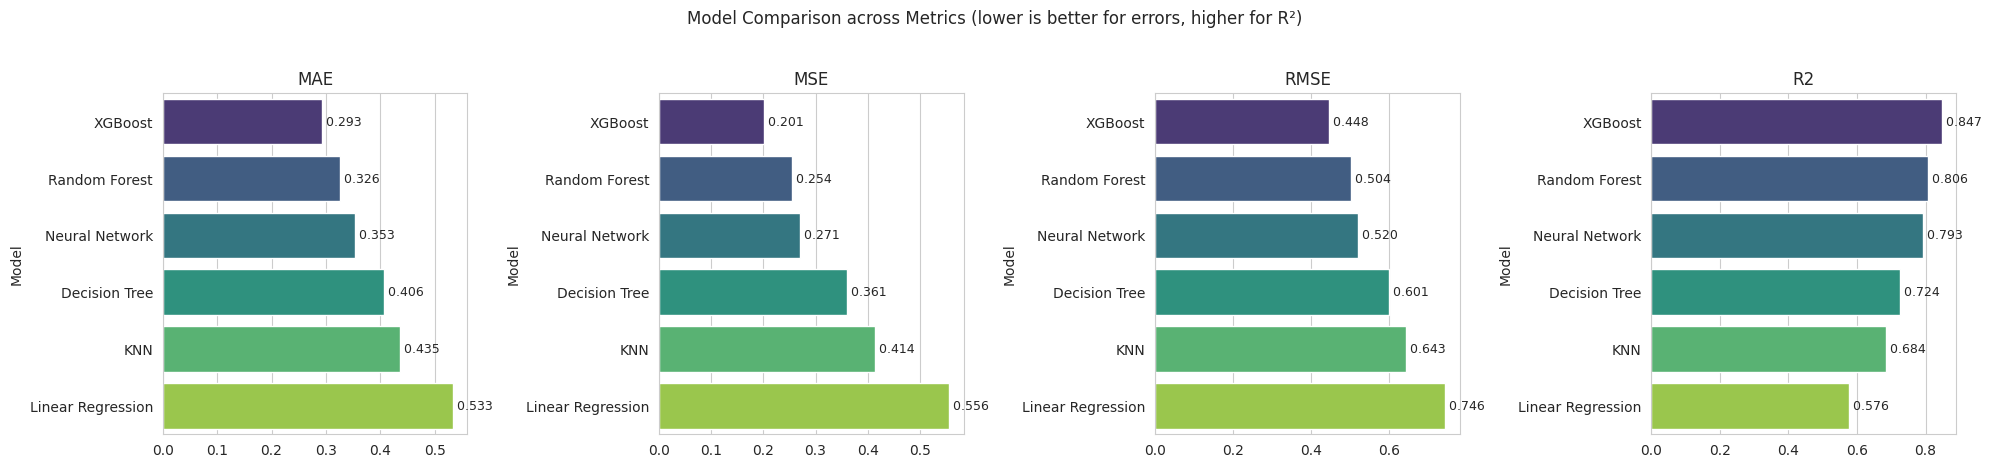

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
palette = sns.color_palette("viridis", len(results_df))
for ax, metric in zip(axes, ["MAE", "MSE", "RMSE", "R2"]):
    order = results_df[metric].sort_values(ascending=(metric != "R2"))
    sns.barplot(x=order.values, y=order.index, ax=ax, palette=palette)
    ax.set_title(metric)
    for i, v in enumerate(order.values):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
plt.suptitle("Model Comparison across Metrics (lower is better for errors, higher for R²)", y=1.03)
plt.tight_layout(); plt.show()

## 8. Actual vs Predicted Values

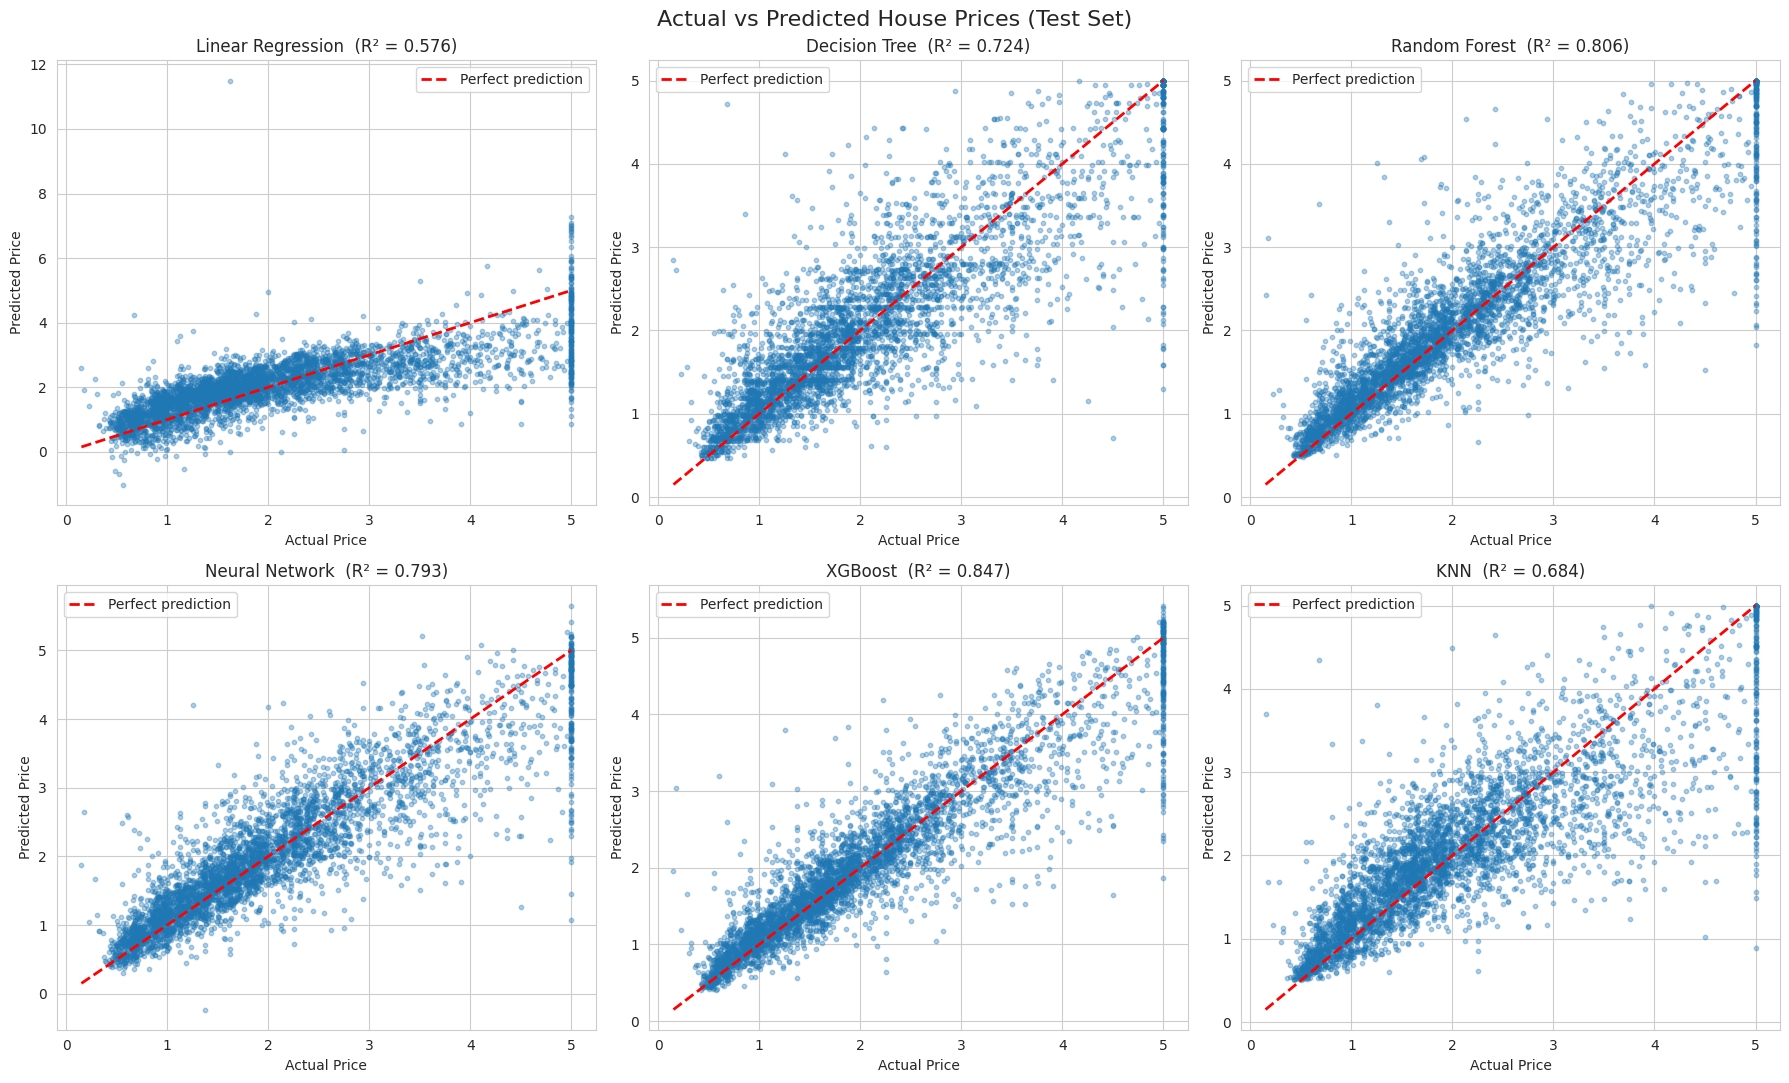

In [ ]:
model_names = list(predictions.keys())
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
lo, hi = y_test.min(), y_test.max()

for ax, name in zip(axes.ravel(), model_names):
    ax.scatter(y_test, predictions[name], alpha=0.35, s=10, color="tab:blue")
    ax.plot([lo, hi], [lo, hi], "r--", lw=2, label="Perfect prediction")
    ax.set_title(f"{name}  (R² = {results[name]['R2']:.3f})")
    ax.set_xlabel("Actual Price"); ax.set_ylabel("Predicted Price"); ax.legend()
plt.suptitle("Actual vs Predicted House Prices (Test Set)", fontsize=16)
plt.tight_layout(); plt.show()

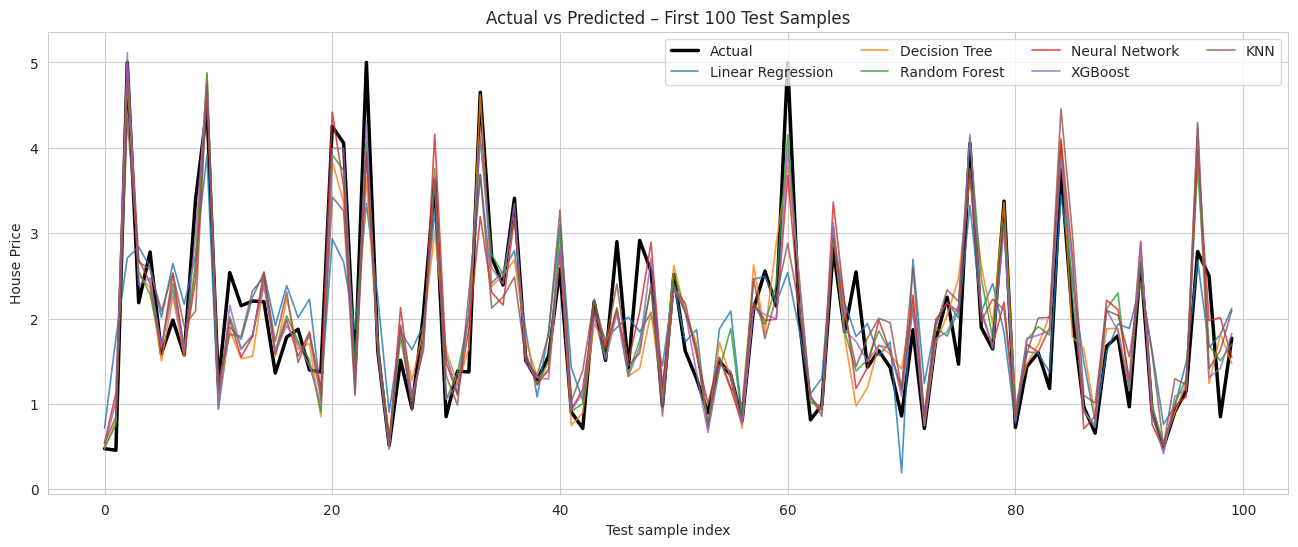

In [ ]:
# Line plot of the first 100 test samples for all models
n = 100
plt.figure(figsize=(16, 6))
plt.plot(range(n), y_test.values[:n], "k-", lw=2.5, label="Actual")
for name in model_names:
    plt.plot(range(n), predictions[name][:n], lw=1.2, alpha=0.8, label=name)
plt.title("Actual vs Predicted – First 100 Test Samples")
plt.xlabel("Test sample index"); plt.ylabel("House Price"); plt.legend(ncol=4)
plt.show()

## 9. Residual Analysis

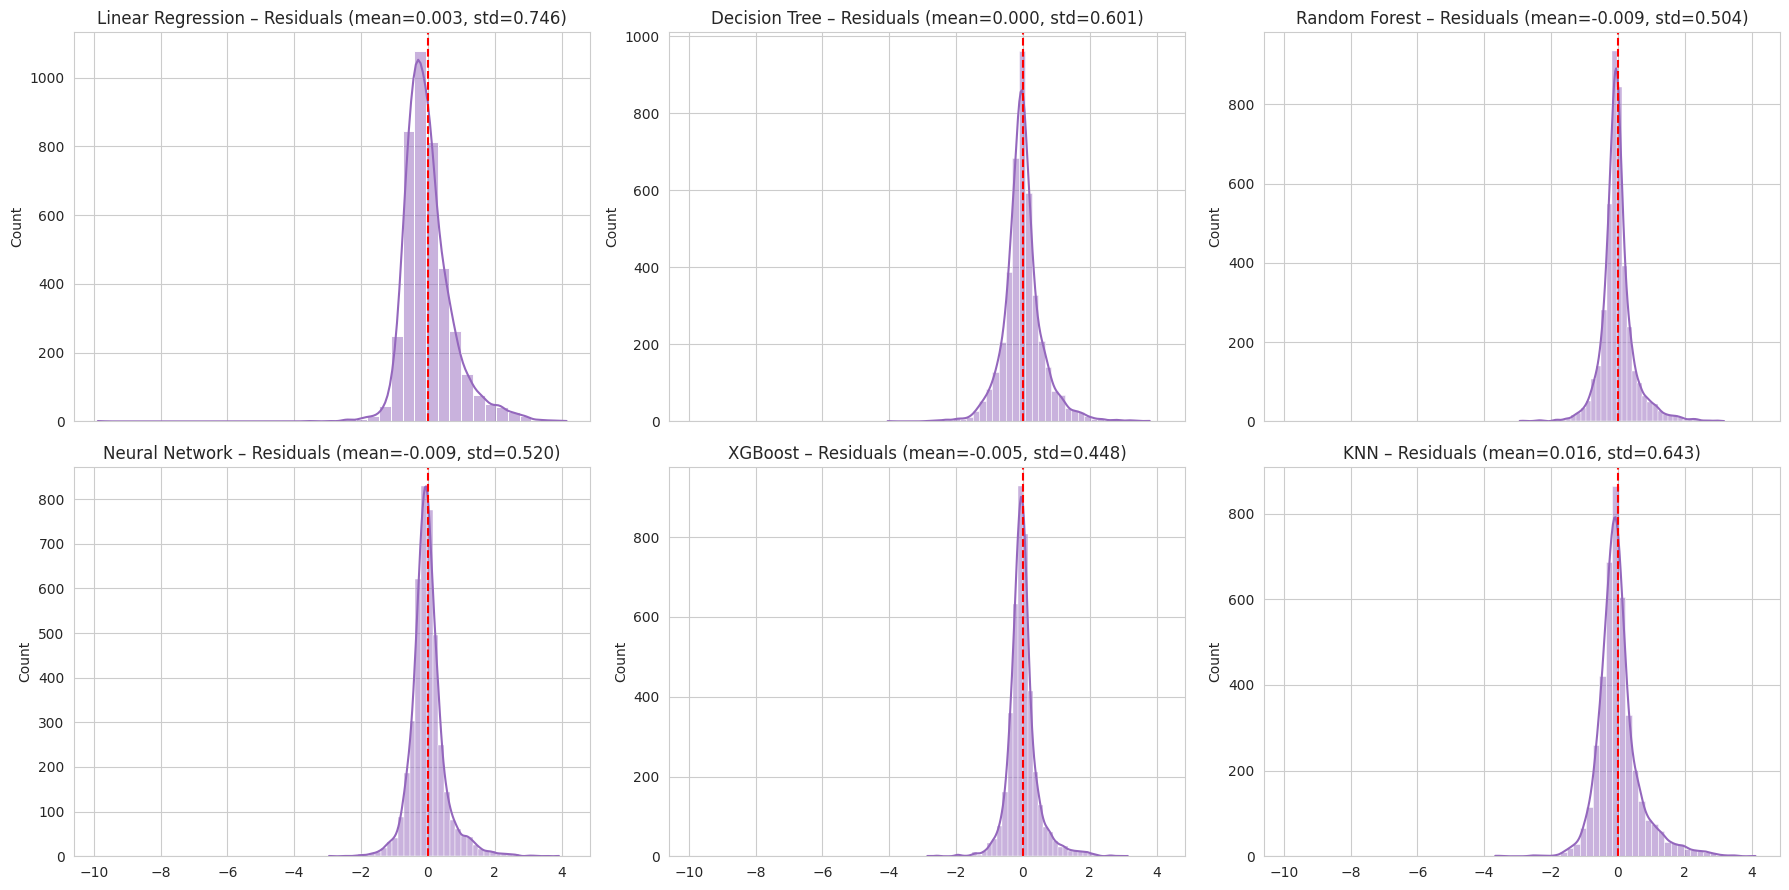

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharex=True)
for ax, name in zip(axes.ravel(), model_names):
    resid = y_test.values - predictions[name]
    sns.histplot(resid, bins=40, kde=True, ax=ax, color="tab:purple")
    ax.axvline(0, color="r", ls="--")
    ax.set_title(f"{name} – Residuals (mean={resid.mean():.3f}, std={resid.std():.3f})")
plt.tight_layout(); plt.show()

## 10. Feature Importance (Tree-based Models)

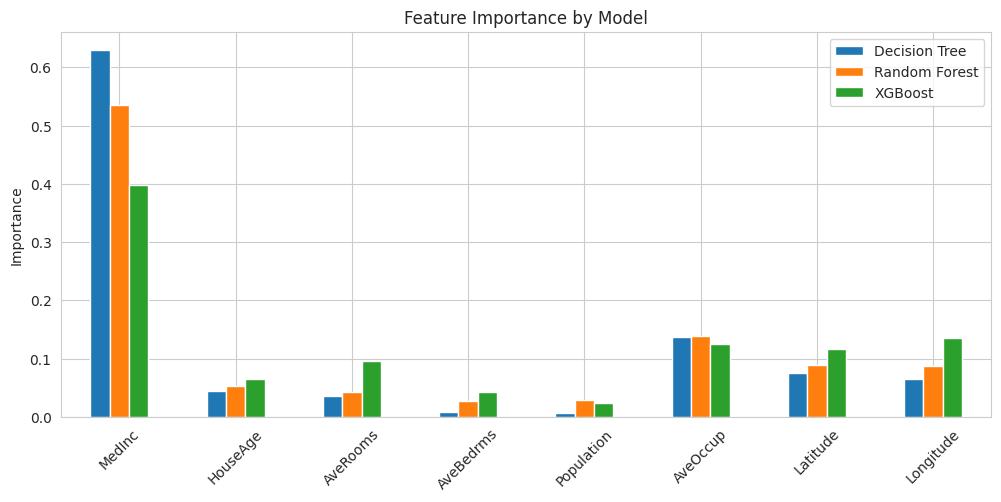

,Decision Tree,Random Forest,XGBoost
MedInc,0.6297,0.5356,0.3972
HouseAge,0.0445,0.0533,0.0657
AveRooms,0.0350,0.0423,0.0951
AveBedrms,0.0087,0.0266,0.0425
Population,0.0058,0.0280,0.0228
AveOccup,0.1363,0.1380,0.1250
Latitude,0.0759,0.0883,0.1158
Longitude,0.0643,0.0878,0.1359


In [ ]:
imp = pd.DataFrame({
    "Decision Tree": dt.feature_importances_,
    "Random Forest": rf.feature_importances_,
    "XGBoost": xgb.feature_importances_}, index=FEATURES)
imp.plot(kind="bar", figsize=(12, 5))
plt.title("Feature Importance by Model"); plt.ylabel("Importance"); plt.xticks(rotation=45)
plt.show()
imp.round(4)

## 11. Strengths and Limitations of Each Algorithm

| Algorithm | Strengths | Limitations |
|---|---|---|
| **Linear Regression** | Very fast, simple, highly interpretable coefficients; low variance; good baseline | Assumes a linear relationship; cannot capture non-linear patterns or interactions; sensitive to outliers and multicollinearity |
| **Decision Tree** | Easy to visualize and interpret; handles non-linearity; no scaling needed | Prone to overfitting; unstable (small data changes alter the tree); piecewise-constant predictions |
| **Random Forest** | Strong accuracy; reduces overfitting through averaging; robust to outliers; gives feature importance | Slower, larger memory use; less interpretable; cannot extrapolate beyond training range |
| **Neural Network** | Can learn complex non-linear relationships; flexible architecture | Needs feature scaling and careful tuning; sensitive to initialization; needs more data; black-box |
| **XGBoost** | Typically the best accuracy on tabular data; built-in regularization; handles missing values; fast | Many hyperparameters to tune; can overfit if untuned; less interpretable |
| **KNN** | No training phase, simple; captures local non-linear patterns | Slow prediction on large data; needs scaling; hurt by irrelevant features / high dimensions; sensitive to choice of k |

## 12. Best Model and Conclusion

In [ ]:
best = results_df["R2"].idxmax()
worst = results_df["R2"].idxmin()
b = results_df.loc[best]

print("=" * 60)
print(f"BEST MODEL  : {best}")
print(f"  R²   = {b['R2']:.4f}  (explains {b['R2']*100:.1f}% of variance in test prices)")
print(f"  RMSE = {b['RMSE']:.4f}  (≈ ${b['RMSE']*100000:,.0f} average error)")
print(f"  MAE  = {b['MAE']:.4f}  (≈ ${b['MAE']*100000:,.0f})")
print(f"WEAKEST MODEL: {worst}  (R² = {results_df.loc[worst, 'R2']:.4f})")
print("=" * 60)
print("\nRanking by R²:")
for i, (m, r) in enumerate(results_df["R2"].items(), 1):
    print(f"  {i}. {m:<20} R² = {r:.4f}")

BEST MODEL  : XGBoost
  R²   = 0.8470  (explains 84.7% of variance in test prices)
  RMSE = 0.4478  (≈ $44,780 average error)
  MAE  = 0.2935  (≈ $29,350)
WEAKEST MODEL: Linear Regression  (R² = 0.5758)

Ranking by R²:
  1. XGBoost              R² = 0.8470
  2. Random Forest        R² = 0.8061
  3. Neural Network       R² = 0.7932
  4. Decision Tree        R² = 0.7244
  5. KNN                  R² = 0.6844
  6. Linear Regression    R² = 0.5758


### Conclusion

The ranking printed above is based entirely on the **test-set results** under identical conditions (same data, same features, same 80:20 split). The best model is the one with the **lowest MAE/MSE/RMSE and highest R²**; the actual-vs-predicted plots support this, since its points cluster most tightly around the red perfect-prediction line and its residuals are the most narrowly centred on zero.

On this kind of tabular housing data, the usual pattern is:
- **Ensemble tree models (XGBoost, Random Forest)** perform best because house prices depend on non-linear effects and interactions (e.g., income × location) that they capture well, while averaging/boosting keeps variance under control.
- **Linear Regression** is the weakest in accuracy, as it cannot model these non-linearities, but it remains the most interpretable baseline.
- **Neural Network and KNN** perform in the middle: good non-linear fit but more sensitive to scaling, tuning and data size.
- A single **Decision Tree** is better than linear regression but less stable than the ensembles.

> Replace/extend this paragraph with your own observations after running the notebook, quoting the actual numbers from the comparison table.